# Experiment 2: (Monte Carlo Percolation Phase Transition on an L x L Lattice):

## Aim
 Using V5 Union-Find (with the dual-UF backwash fix), simulate site percolation on an Lx L grid for L {40, 80, 160}. Sweep open probability p € [0.45,0.75] in steps of 0.01 (running 100 random trials per p) and plot the empirical percolation probability P(percolates | p) versus p, verifying the sharp sigmoid phase transition at pe0.593.



## 1. Import the required library

- `random` generates random values to decide whether a cell opens.
- `matplotlib.pyplot` is used to draw the graph.

In [3]:
import random
import matplotlib.pyplot as plt

## 2. Union-Find class

Each element starts in its own group.

- `parent` stores the parent of each element.
- `rank` stores an estimate of the height of each tree.
- `find(x)` returns the main parent (root) of the group containing `x`.
- `union(a, b)` joins the groups containing `a` and `b`.
- `connected(a, b)` checks whether two elements are in the same group.

This class uses **union by rank** and **path compression** to keep the trees short.

In [1]:
class UnionFind:

    def __init__(self, n):
        self.parent = list(range(n))
        self.rank = [0] * n

    def find(self, x):

        if self.parent[x] == x:
            return x

        self.parent[x] = self.find(self.parent[x])
        return self.parent[x]

    def union(self, a, b):

        par_a = self.find(a)
        par_b = self.find(b)

        if par_a == par_b:
            return

        if self.rank[par_a] > self.rank[par_b]:
            self.parent[par_b] = par_a

        elif self.rank[par_a] < self.rank[par_b]:
            self.parent[par_a] = par_b

        else:
            self.parent[par_b] = par_a
            self.rank[par_a] = self.rank[par_a] + 1

    def connected(self, a, b):
        return self.find(a) == self.find(b)

## 3. Virtual top and bottom

For a grid with `L` rows and `L` columns:

- Total number of real cells: `N = L * L`
- Real cells are numbered from `0` to `N - 1`.
- Virtual top is numbered `N`.
- Virtual bottom is numbered `N + 1`.

The virtual points are extra Union-Find elements; they are not real grid cells.

For example, when `L = 3`, the real cells are `0` to `8`, the virtual top is `9`, and the virtual bottom is `10`.

## 4. One percolation trial

A trial creates a fresh grid. Each cell is opened with probability `P`.

We use two Union-Find objects:

- `uf_percolation` has the real cells, virtual top and virtual bottom. It checks whether the grid percolates.
- `uf_full` has the real cells and virtual top only. It is used for fullness checks and avoids the Backwash Bug.

We check the cell above and the cell to the left. Since we visit the grid from top to bottom and left to right, these neighbours have already been visited.

In [4]:
def percolation_trial(L, P):

    n = L * L

    virtual_top = n
    virtual_bottom = n + 1

    uf_percolation = UnionFind(n + 2)
    uf_full = UnionFind(n + 1)

    # False means blocked; True means open
    opened = [False] * n

    for row in range(L):
        for col in range(L):

            # Open this cell with probability P
            if random.random() < P:

                cell = row * L + col
                opened[cell] = True

                # Connect top-row cells to the virtual top
                if row == 0:
                    uf_percolation.union(cell, virtual_top)
                    uf_full.union(cell, virtual_top)

                # Connect bottom-row cells to virtual bottom
                # only in the percolation object
                if row == L - 1:
                    uf_percolation.union(cell, virtual_bottom)

                # Check the cell above
                if row > 0:
                    above = (row - 1) * L + col

                    if opened[above]:
                        uf_percolation.union(cell, above)
                        uf_full.union(cell, above)

                # Check the cell on the left
                if col > 0:
                    left = row * L + (col - 1)

                    if opened[left]:
                        uf_percolation.union(cell, left)
                        uf_full.union(cell, left)

                # Has a path reached from top to bottom?
                if uf_percolation.connected(virtual_top, virtual_bottom):
                    return True

    return False

### What does the trial function return?

- `True`: there is an open path from the top row to the bottom row.
- `False`: no such path was found after all cells were checked.

Each call to `percolation_trial()` is one independent experiment.

## 5. Backwash Bug

The Backwash Bug can happen if one Union-Find object is used for both percolation and fullness.

Imagine that one open path connects the top to the bottom. Another open cell is on the bottom row but has no open path to the top. If both bottom-row cells connect to the same virtual bottom, the second cell can incorrectly appear connected to the top.

| Union-Find object | Virtual top | Virtual bottom |
|---|---:|---:|
| `uf_percolation` | Yes | Yes |
| `uf_full` | Yes | No |

For a fullness check, the cell must be open and connected to the virtual top in `uf_full`:

```python
is_full = opened[cell] and uf_full.connected(virtual_top, cell)
```

The separate `uf_full` object avoids the Backwash Bug.

## 6. Run the Monte Carlo simulation

We test:
- Grid sizes: `40`, `80`, and `160`.
- Open probabilities: `0.45` to `0.75`, increasing by `0.01`.
- Trials: `100` for every grid-size and probability combination.

For each combination, `count` records how many trials percolate. Dividing by the number of trials gives the empirical percolation probability.

In [5]:
grid_sizes = [40, 80, 160]

trials = 100

results = {}

for L in grid_sizes:

    results[L] = []

    print("Grid size:", L)

    p = 0.45

    while p <= 0.75:

        count = 0

        for i in range(trials):

            if percolation_trial(L, p):
                count = count + 1

        probability = count / trials
        results[L].append(probability)

        print("p =", round(p, 2), "Result =", probability)

        p = round(p + 0.01, 2)

print("Simulation completed!")

Grid size: 40
p = 0.45 Result = 0.0
p = 0.46 Result = 0.0
p = 0.47 Result = 0.0
p = 0.48 Result = 0.0
p = 0.49 Result = 0.0
p = 0.5 Result = 0.0
p = 0.51 Result = 0.01
p = 0.52 Result = 0.01
p = 0.53 Result = 0.04
p = 0.54 Result = 0.11
p = 0.55 Result = 0.19
p = 0.56 Result = 0.11
p = 0.57 Result = 0.26
p = 0.58 Result = 0.34
p = 0.59 Result = 0.47
p = 0.6 Result = 0.59
p = 0.61 Result = 0.71
p = 0.62 Result = 0.84
p = 0.63 Result = 0.84
p = 0.64 Result = 0.91
p = 0.65 Result = 0.96
p = 0.66 Result = 0.97
p = 0.67 Result = 0.99
p = 0.68 Result = 1.0
p = 0.69 Result = 1.0
p = 0.7 Result = 1.0
p = 0.71 Result = 1.0
p = 0.72 Result = 1.0
p = 0.73 Result = 1.0
p = 0.74 Result = 1.0
p = 0.75 Result = 1.0
Grid size: 80
p = 0.45 Result = 0.0
p = 0.46 Result = 0.0
p = 0.47 Result = 0.0
p = 0.48 Result = 0.0
p = 0.49 Result = 0.0
p = 0.5 Result = 0.0
p = 0.51 Result = 0.0
p = 0.52 Result = 0.0
p = 0.53 Result = 0.0
p = 0.54 Result = 0.0
p = 0.55 Result = 0.02
p = 0.56 Result = 0.07
p = 0.57 Re

## 7. Plot the results

The graph contains:
- One line for each grid size.
- Open probability on the x-axis.
- Empirical percolation probability on the y-axis.
- A vertical dashed line at the theoretical critical probability, approximately `0.593`.

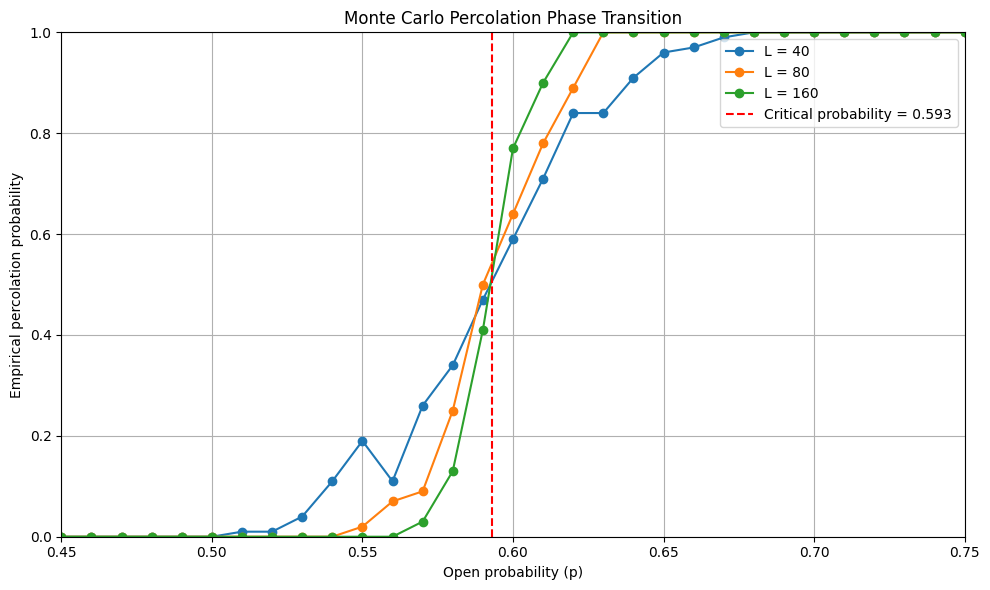

In [6]:
# Values of p used in the simulation
probabilities = []

p = 0.45

while p <= 0.75:
    probabilities.append(round(p, 2))
    p = round(p + 0.01, 2)

plt.figure(figsize=(10, 6))

for L in grid_sizes:
    plt.plot(probabilities, results[L], marker='o', label=f'L = {L}')

# Theoretical critical probability
plt.axvline(0.593, color='red', linestyle='--',
            label='Critical probability = 0.593')

plt.xlabel("Open probability (p)")
plt.ylabel("Empirical percolation probability")
plt.title("Monte Carlo Percolation Phase Transition")

plt.xlim(0.45, 0.75)
plt.ylim(0, 1)

plt.grid(True)
plt.legend()
plt.tight_layout()

plt.savefig("percolation_graph.png", dpi=300)
plt.show()